# Итоговый проект: гибридная система рекомендаций книг

**Автор:** Александра Бужор · [@Angry_C_F_O](https://t.me/Angry_C_F_O)

Проект объединяет Popularity, Content-Based, Item-Based CF и SVD из домашней работы с Two-Tower нейросетью, сегментным взвешиванием и MMR-диверсификацией. Notebook воспроизводит анализ зафиксированного pipeline; обучение выполняется командой `python scripts/train.py`.

In [1]:
from pathlib import Path
import json
import joblib
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / 'artifacts').exists():
    ROOT = ROOT.parent
ARTIFACTS = ROOT / 'artifacts'
REPORTS = ROOT / 'reports'
config = json.loads((ARTIFACTS / 'config.json').read_text(encoding='utf-8'))
metrics = pd.read_csv(ARTIFACTS / 'metrics.csv')
segments = pd.read_csv(ARTIFACTS / 'segment_metrics.csv')
print(config['project'], config['version'])

hybrid-book-recommender 2.0.0


## 1. Протокол и контроль утечки

Дубли удаляются до split. Модели обучаются на train; веса и MMR-параметр выбираются на validation; test используется для финального сравнения. Релевантна оценка ≥4. Метрики макроусредняются по одной и той же выборке пользователей, train-книги исключаются.

In [2]:
pd.DataFrame([
    {'split': key, 'rows': value}
    for key, value in config['split'].items() if key.endswith('_rows')
])

,split,rows
0,train_rows,761605
1,validation_rows,104958
2,test_rows,112915


## 2. Расширенные признаки

Пользовательские признаки описывают активность и распределение оценок. Книжные — популярность, байесовский рейтинг, разнообразие оценок и тематические теги. Все рейтинговые статистики получены только из train. Для пары пользователь–книга дополнительно рассчитываются content similarity, Item-CF score и тематическая близость к истории.

In [3]:
users = pd.read_csv(ROOT / 'data/processed/user_features.csv.gz')
books = pd.read_csv(ROOT / 'data/processed/book_features.csv.gz')
print('User features:', config['features']['user'])
print('Book features:', config['features']['book'])
display(users.head())
display(books.head())
display(pd.read_csv(ARTIFACTS / 'interaction_features_example.csv'))

User features: ['log_rating_count', 'mean_rating', 'rating_std', 'positive_ratio', 'negative_ratio', 'rating_entropy', 'activity_score']
Book features: ['log_rating_count', 'bayesian_mean', 'rating_std', 'positive_ratio', 'rating_entropy', 'popularity_score', 'global_log_ratings_count', 'publication_year', 'topic_fiction', 'topic_fantasy', 'topic_science_fiction', 'topic_romance', 'topic_mystery', 'topic_history', 'topic_children', 'topic_young_adult', 'topic_nonfiction', 'topic_comics']


,user_id,rating_count,log_rating_count,mean_rating,rating_std,positive_ratio,negative_ratio,rating_entropy,activity_score,segment
0,1,2,1.098612,3.5,0.707107,0.50,0.0,0.430677,0.216202,new
1,2,2,1.098612,4.5,0.707107,1.00,0.0,0.430677,0.216202,new
2,3,1,0.693147,1.0,0.000000,0.00,1.0,-0.000000,0.136409,new
3,4,2,1.098612,3.5,2.121320,0.50,0.5,0.430677,0.216202,new
4,5,4,1.609438,4.0,0.816497,0.75,0.0,0.646015,0.316731,warm


,book_id,rating_count,log_rating_count,bayesian_mean,rating_std,positive_ratio,rating_entropy,popularity_score,global_log_ratings_count,publication_year,topic_fiction,topic_fantasy,topic_science_fiction,topic_romance,topic_mystery,topic_history,topic_children,topic_young_adult,topic_nonfiction,topic_comics
0,1,82,4.418840,4.177562,0.886260,0.853659,0.689968,0.974902,15.380088,2008.0,0.229548,0.113026,0.257362,0.040096,0.012138,0.000000,0.000000,0.273931,0.073891,0.0
1,2,90,4.510859,4.155558,1.046962,0.833333,0.729980,0.995204,15.342106,1997.0,0.153670,0.521340,0.024344,0.000000,0.006026,0.000000,0.131381,0.159844,0.003385,0.0
2,3,82,4.418840,3.275602,1.488741,0.451220,0.974929,0.974902,15.167948,2005.0,0.164654,0.336074,0.026733,0.061017,0.000000,0.000000,0.000000,0.406654,0.004848,0.0
3,4,81,4.406719,4.367439,0.808138,0.864198,0.570205,0.972228,14.978246,1960.0,0.588058,0.000000,0.000000,0.000000,0.021990,0.256547,0.000000,0.133365,0.000000,0.0
4,5,70,4.262680,3.823460,1.107195,0.671429,0.854347,0.940449,14.802694,1925.0,0.819695,0.000000,0.000000,0.068980,0.000000,0.099347,0.000000,0.011948,0.000000,0.0


,user_id,book_id,content_history_similarity,item_cf_score,topic_affinity,user_mean_rating,book_log_popularity
0,6630,243,0.232353,0.0,0.285428,3.566879,4.369448
1,6630,209,0.222699,0.0,0.238716,3.566879,4.369448
2,6630,2352,0.220938,0.0,0.287497,3.566879,4.418840
3,6630,6361,0.000000,0.0,0.095602,3.566879,4.330733
4,6630,7927,0.204220,0.0,0.120924,3.566879,4.454347
5,6630,201,0.204351,0.0,0.249131,3.566879,4.454347
6,6630,3177,0.000000,5.0,0.124584,3.566879,4.394449
7,6630,7947,0.000000,0.0,0.176893,3.566879,4.189655
8,6630,944,0.209279,0.0,0.301245,3.566879,4.330733
9,6630,4067,0.202909,0.0,0.228841,3.566879,4.394449


## 3. Метрики

$Precision@K = |TopK \cap Relevant|/K$

$Recall@K = |TopK \cap Relevant|/|Relevant|$

$nDCG@K = DCG@K/IDCG@K$, где релевантность бинарна, а $IDCG$ соответствует идеальному порядку. ILD измеряет среднее попарное `1 − cosine` внутри списка; Coverage — покрытие каталога.

In [4]:
columns = ['model', 'precision_at_k', 'recall_at_k', 'ndcg_at_k', 'ild_at_k', 'novelty_at_k', 'catalog_coverage']
metrics[columns].sort_values('ndcg_at_k', ascending=False).reset_index(drop=True)

,model,precision_at_k,recall_at_k,ndcg_at_k,ild_at_k,novelty_at_k,catalog_coverage
0,Content-Based,0.033667,0.209283,0.140429,0.829936,13.285958,0.3527
1,Hybrid (no MMR),0.031000,0.197745,0.135385,0.851762,13.290372,0.3431
2,Hybrid-Classical,0.030833,0.198935,0.134872,0.851187,13.289636,0.3426
3,Hybrid,0.026333,0.172736,0.121844,0.908278,13.308720,0.3482
4,Item-Based CF,0.004167,0.030060,0.014116,0.936417,13.295897,0.3691
5,Two-Tower,0.003000,0.014251,0.007514,0.941762,13.408564,0.1866
6,SVD,0.000333,0.000583,0.000402,0.834825,13.342209,0.0058
7,Popularity,0.000167,0.000417,0.000232,0.828300,13.307837,0.0011


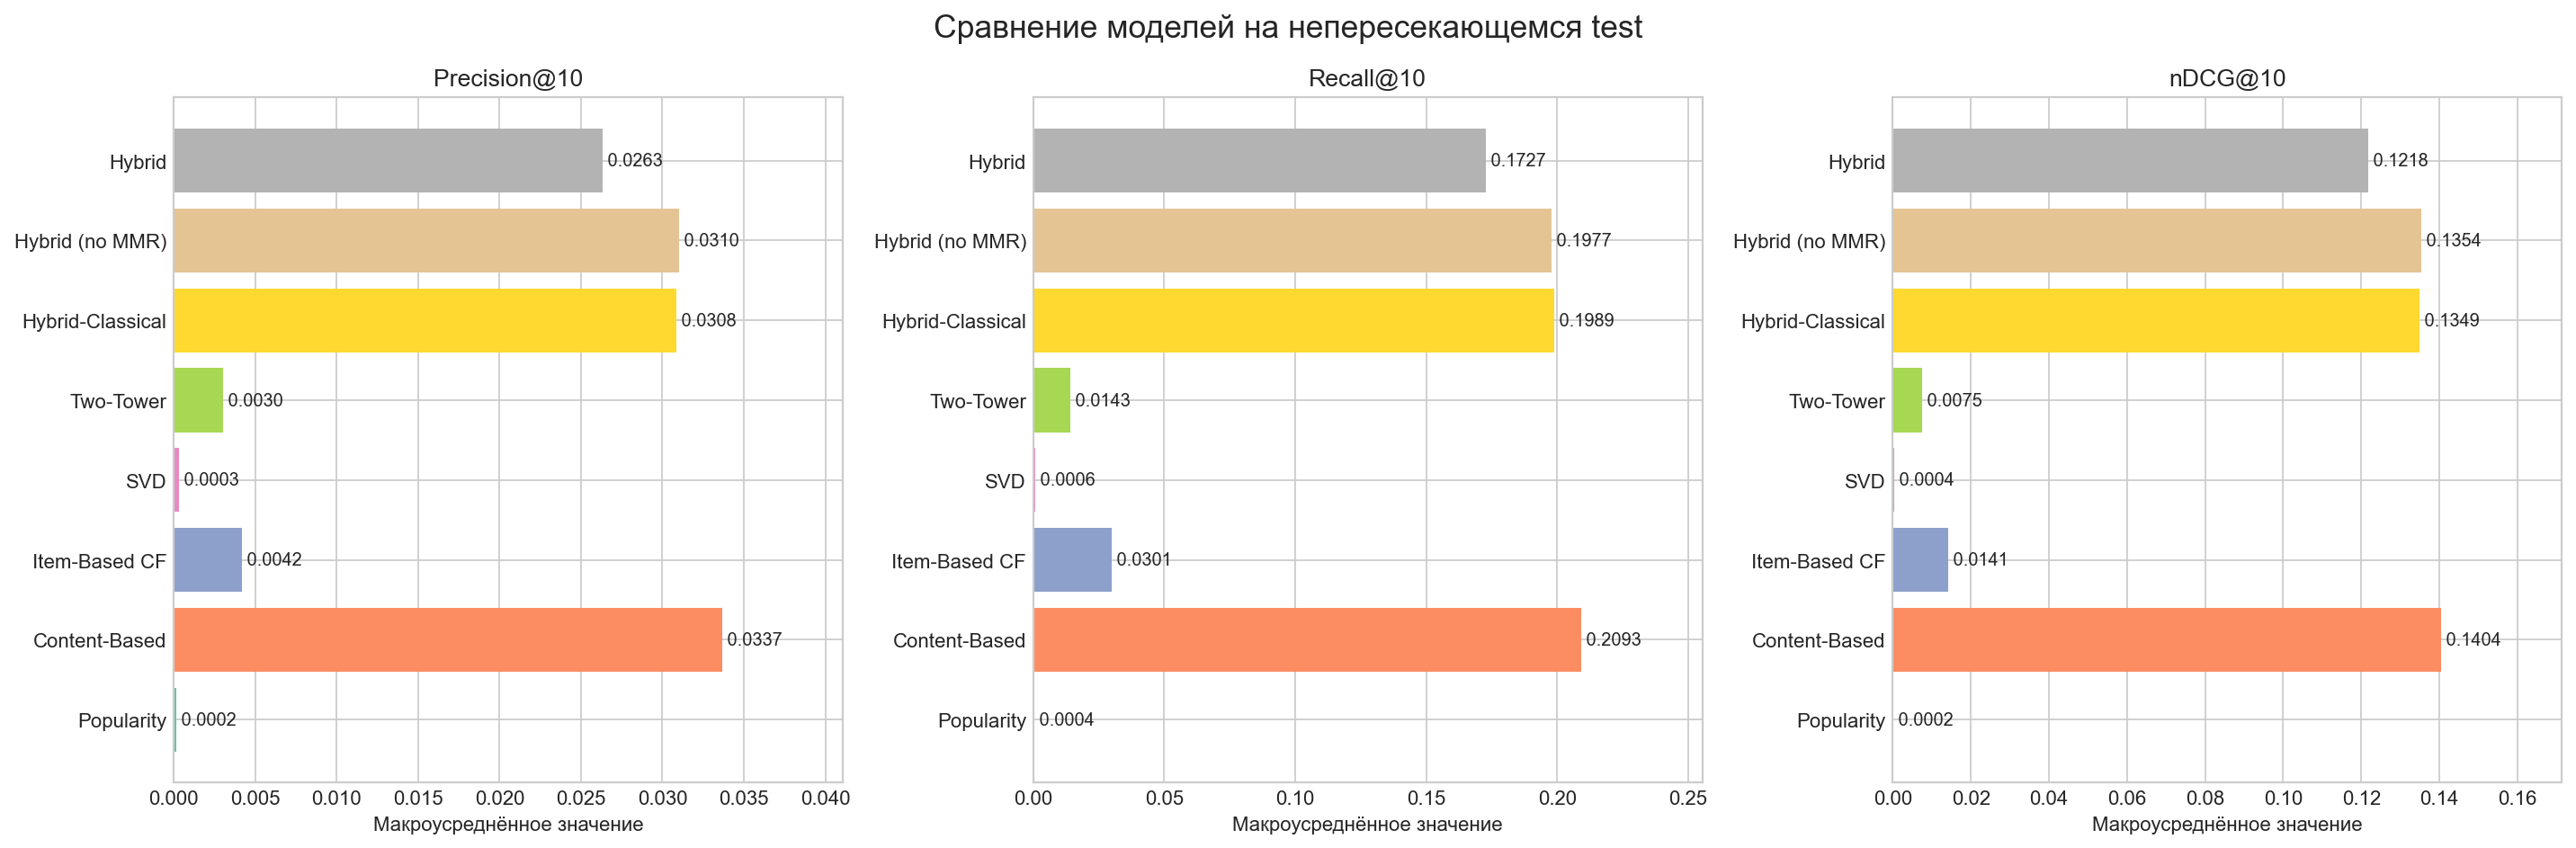

In [5]:
display(Image(filename=str(REPORTS / 'figures/06_model_comparison.png')))

## 4. Two-Tower: архитектура и обучение

Обучаемые ID-embeddings и непрерывные признаки каждой сущности проходят отдельную dense+tanh башню. Score — dot product. BPR максимизирует разницу `score(user, positive) − score(user, sampled_negative)`. Градиенты и Adam реализованы на NumPy. График показывает фактические train loss и pairwise accuracy; это не validation-метрики.

,epoch,train_bpr_loss,train_bpr_accuracy
0,1,0.617161,0.676652
1,2,0.389518,0.823886
2,3,0.297521,0.870007
3,4,0.252510,0.891421


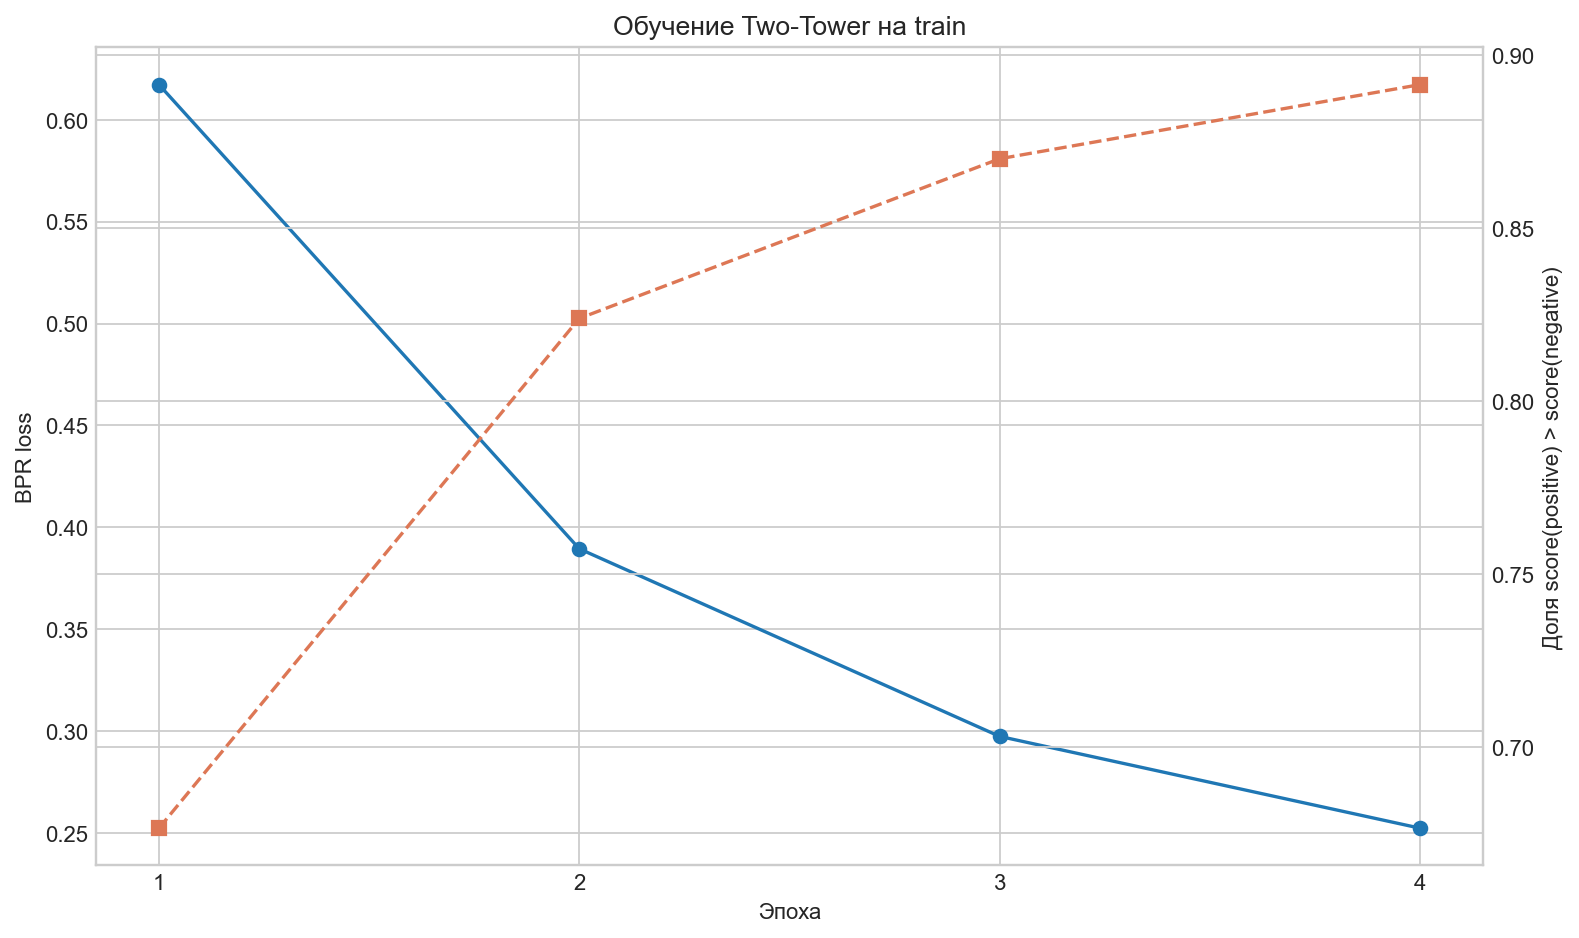

In [6]:
history = pd.read_csv(ARTIFACTS / 'neural_history.csv')
display(history)
display(Image(filename=str(REPORTS / 'figures/11_neural_training.png')))

## 4.1. Feature ablation: действительно ли помогают признаки

Сравниваются четыре варианта: только ID, ID + пользовательские признаки, ID + книжные признаки и полный набор. Train, seed, размерности сети, BPR-параметры и 600 test-пользователей совпадают. Отключённые стандартизованные признаки заменяются нулями (средними train-значениями), поэтому архитектура и инициализация остаются сопоставимыми. Полная модель используется та же, что и в гибриде. Веса гибрида по этим результатам не перенастраиваются.

,model,precision_at_k,recall_at_k,ndcg_at_k,delta_ndcg_vs_id_only,ild_at_k
0,Two-Tower ID only,0.000667,0.004444,0.003829,0.000000,0.966676
1,Two-Tower + user features,0.000833,0.004282,0.002657,-0.001173,0.962845
2,Two-Tower + item features,0.003333,0.014767,0.007185,0.003355,0.937450
3,Two-Tower full features,0.003000,0.014251,0.007514,0.003684,0.941762


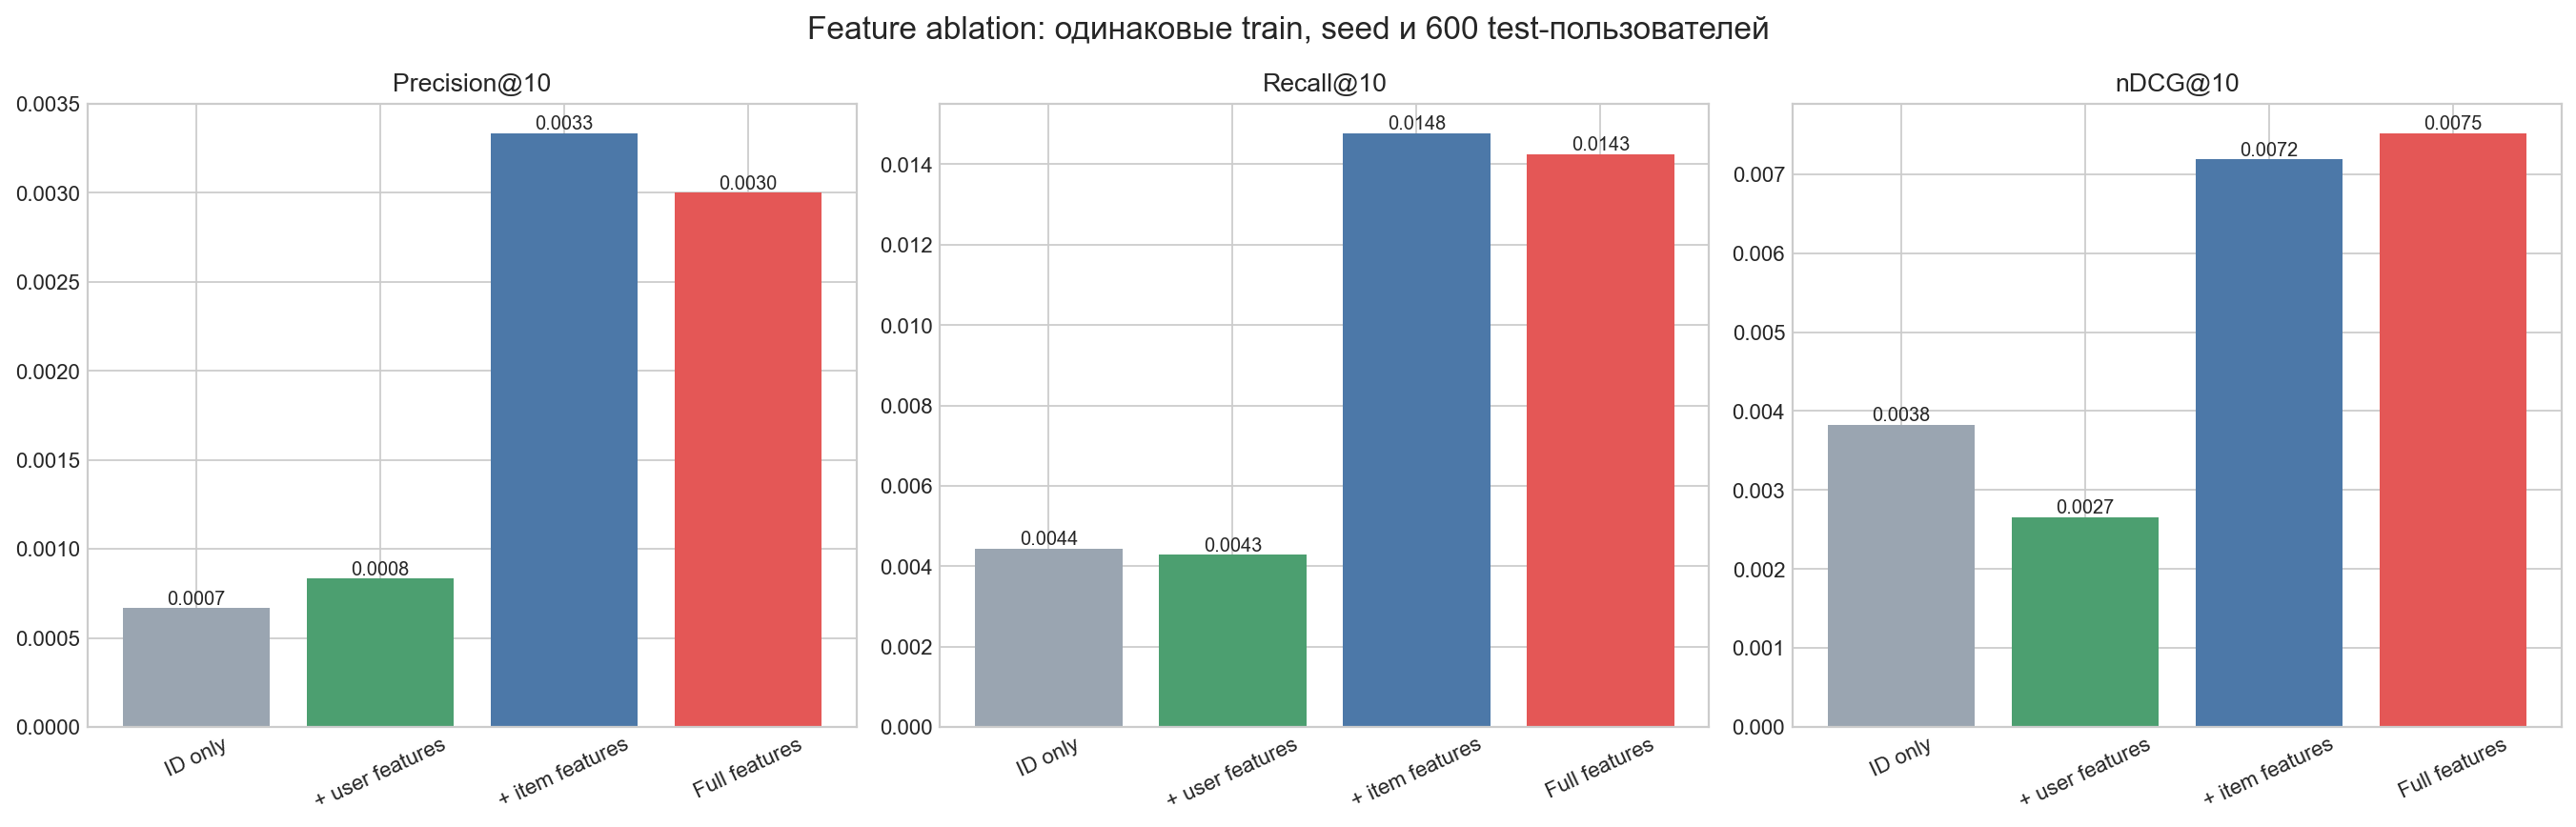

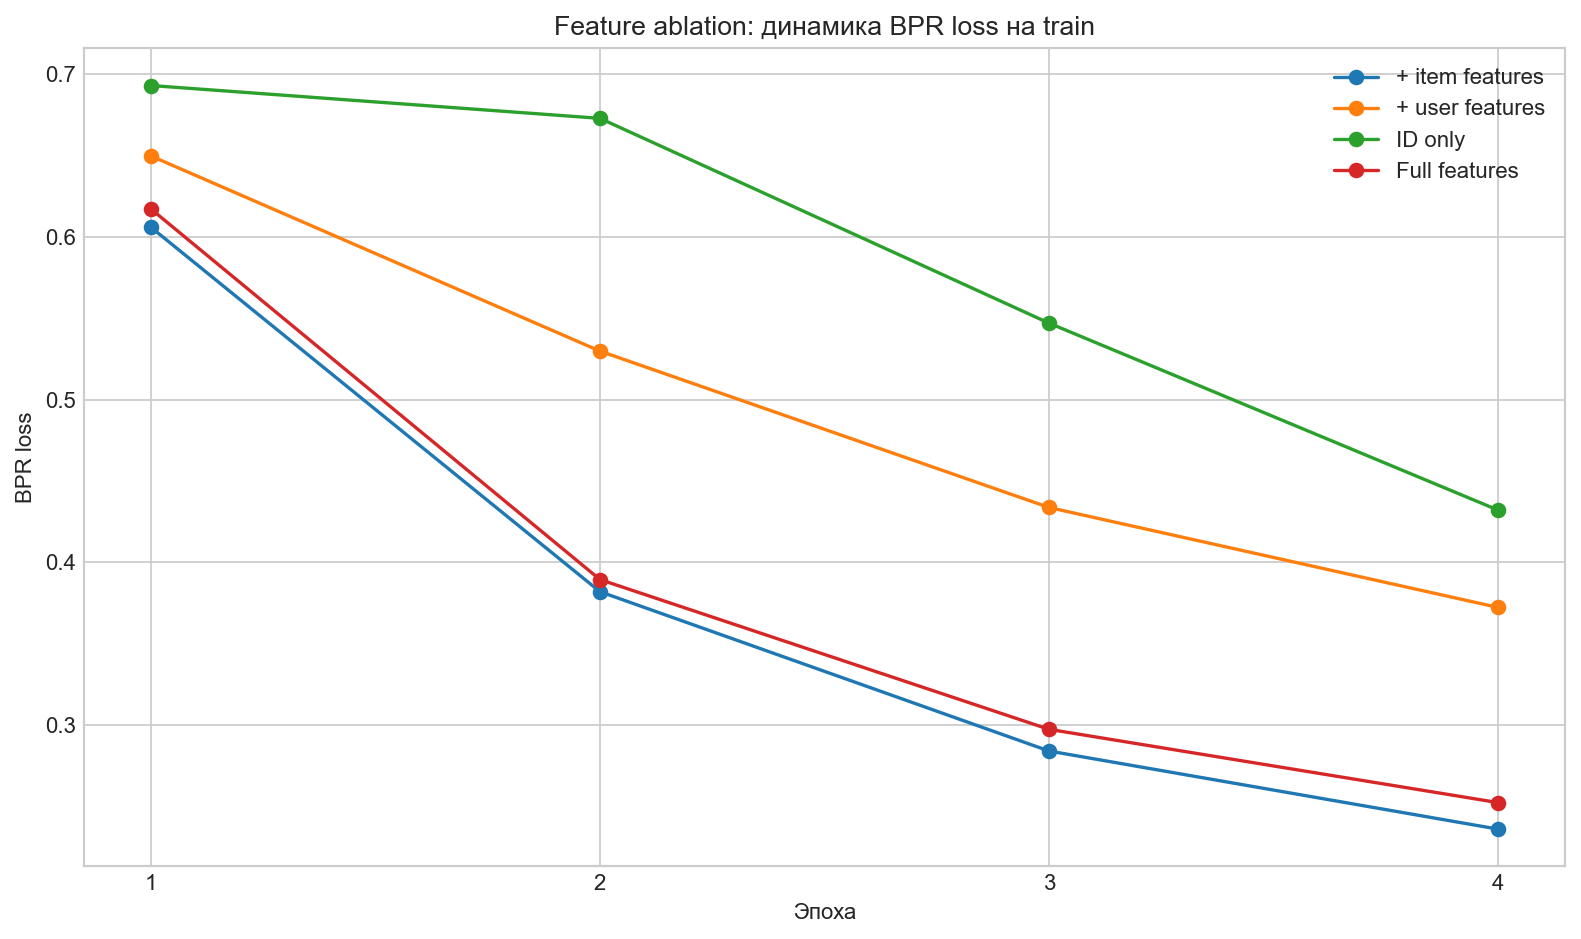

Полный набор vs ID-only, Δ nDCG@10: +0.00368442
Относительный эффект полного набора: +96.21%
Пользовательские признаки vs ID-only, Δ nDCG@10: -0.00117271
Книжные признаки vs ID-only, Δ nDCG@10: +0.00335533
Лидер по nDCG@10: Two-Tower full features
Вывод относится к текущим split и seed; веса гибрида по test не перенастраиваются.


In [7]:
ablation_path = ARTIFACTS / 'feature_ablation_metrics.csv'
if ablation_path.exists():
    ablation = pd.read_csv(ablation_path)
    base = ablation.set_index('model').loc['Two-Tower ID only', 'ndcg_at_k']
    ablation['delta_ndcg_vs_id_only'] = ablation['ndcg_at_k'] - base
    display(ablation[['model', 'precision_at_k', 'recall_at_k', 'ndcg_at_k', 'delta_ndcg_vs_id_only', 'ild_at_k']])
    display(Image(filename=str(REPORTS / 'figures/12_feature_ablation.png')))
    display(Image(filename=str(REPORTS / 'figures/13_feature_ablation_training.png')))
    indexed_ablation = ablation.set_index('model')
    full = indexed_ablation.loc['Two-Tower full features', 'ndcg_at_k']
    user = indexed_ablation.loc['Two-Tower + user features', 'ndcg_at_k']
    item = indexed_ablation.loc['Two-Tower + item features', 'ndcg_at_k']
    print(f'Полный набор vs ID-only, Δ nDCG@10: {full - base:+.8f}')
    relative = f'{(full - base) / base:+.2%}' if base else 'не определён'
    print('Относительный эффект полного набора:', relative)
    print(f'Пользовательские признаки vs ID-only, Δ nDCG@10: {user - base:+.8f}')
    print(f'Книжные признаки vs ID-only, Δ nDCG@10: {item - base:+.8f}')
    print('Лидер по nDCG@10:', indexed_ablation['ndcg_at_k'].idxmax())
    print('Вывод относится к текущим split и seed; веса гибрида по test не перенастраиваются.')
else:
    print('Feature ablation ещё не запущен: python scripts/feature_ablation.py')

## 5. Гибрид: кандидаты, веса и разнообразие

Модели формируют общий пул кандидатов. Score каждой модели min-max нормализуется, затем применяются сегментные веса. MMR использует `λ·relevance − (1−λ)·max_similarity`. Коэффициент diversity objective равен 0.20 и задан до просмотра test. Hybrid-Classical и Hybrid (no MMR) — ablation-контроли.

MMR lambda: 0.7


,popularity,content,item_cf,svd,two_tower
segment,,,,,
cold_start,1.000000,0.000000,0.000000,0.000000,0.000000
new,0.200000,0.500000,0.050000,0.100000,0.150000
warm,0.000000,1.000000,0.000000,0.000000,0.000000
active,0.196231,0.471851,0.226733,0.025096,0.080088


,diversity_lambda,ndcg_at_k,ild_at_k,validation_objective,users
0,0.60,0.072586,0.917856,0.256157,120
1,0.70,0.076105,0.903678,0.256841,120
2,0.80,0.076996,0.887972,0.254590,120
3,0.85,0.078194,0.881264,0.254447,120
4,0.90,0.082474,0.871775,0.256829,120
5,1.00,0.084099,0.858703,0.255840,120


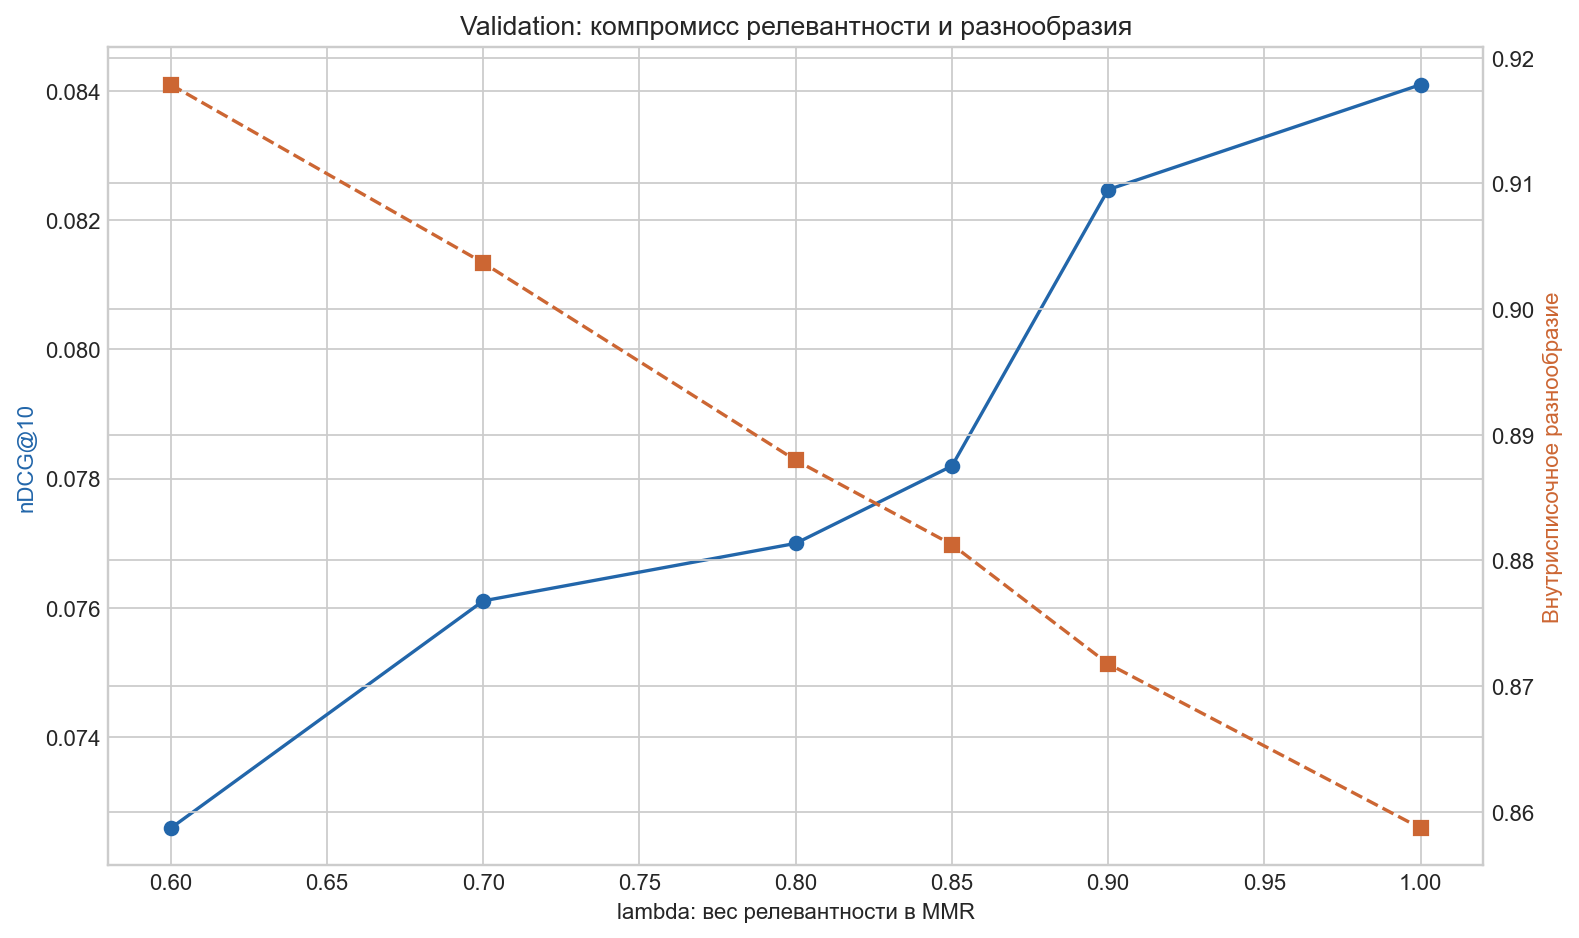

In [8]:
weights = pd.DataFrame(config['hybrid']['weights']).T
weights.index.name = 'segment'
print('MMR lambda:', config['hybrid']['diversity_lambda'])
display(weights)
display(pd.read_csv(ARTIFACTS / 'validation_diversity_search.csv'))
display(Image(filename=str(REPORTS / 'figures/09_diversity_tradeoff.png')))

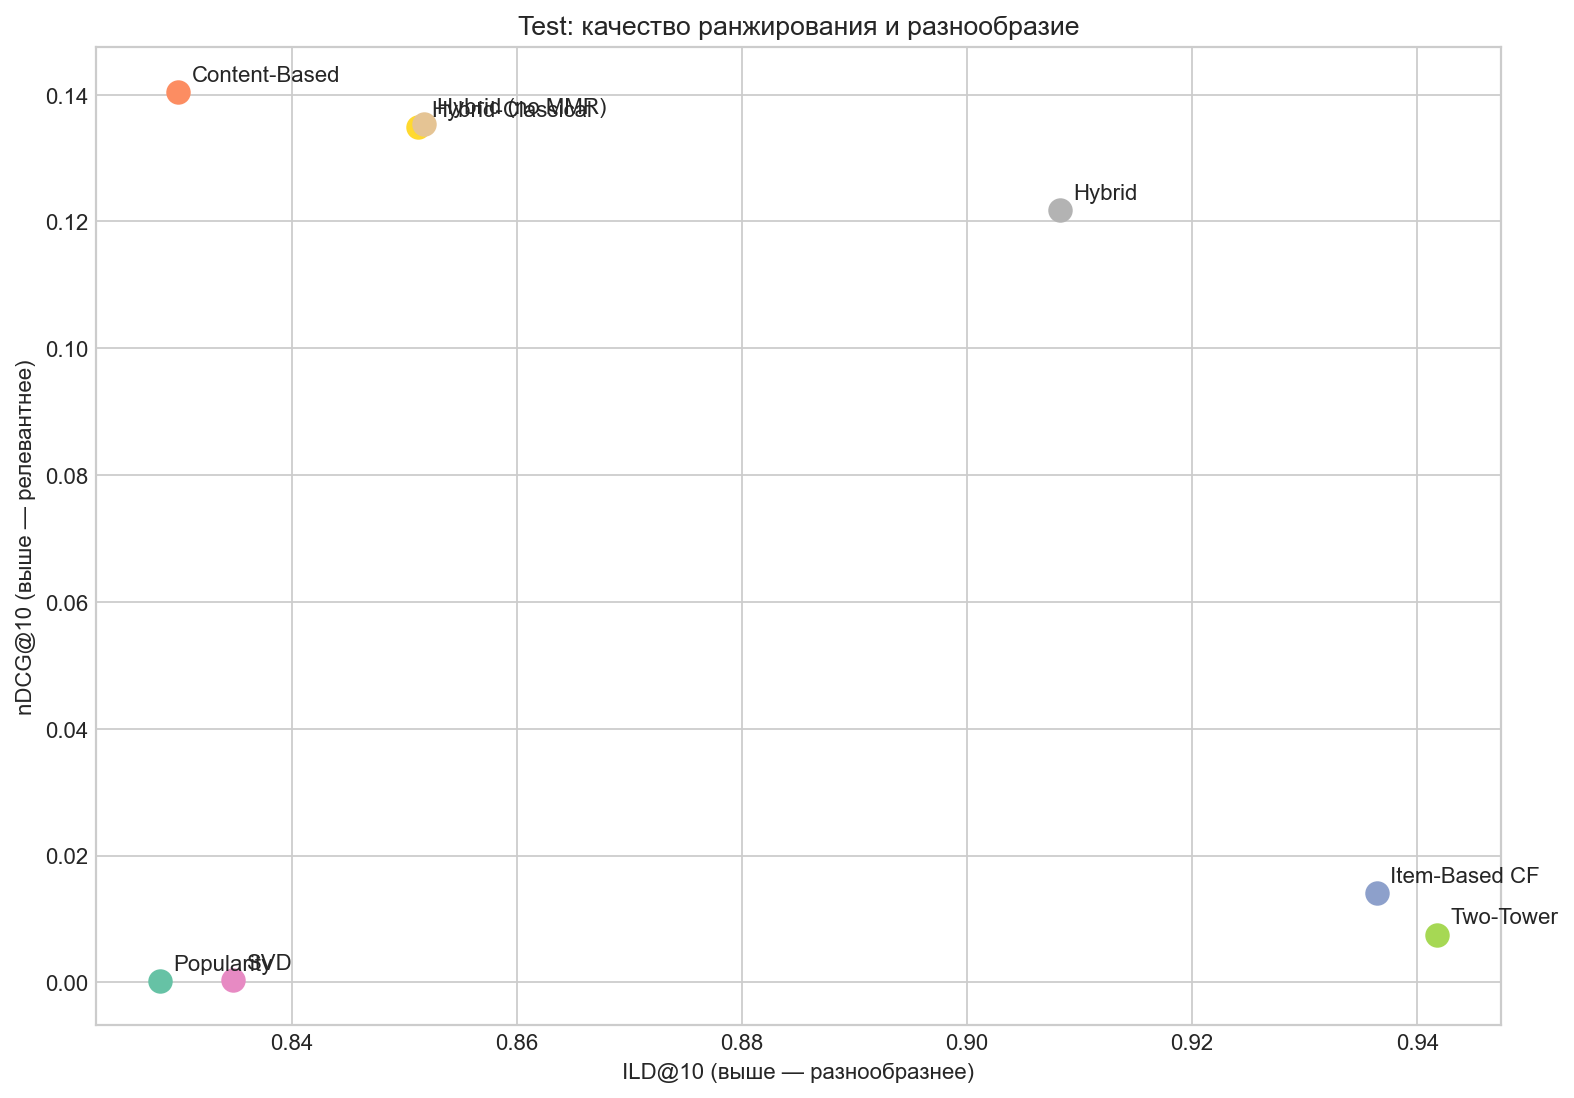

In [9]:
display(Image(filename=str(REPORTS / 'figures/10_quality_diversity_map.png')))

## 6. Сегментный анализ

New: 1–2 train-оценки; warm: 3–9; active: ≥10. У new недостаточно validation-наблюдений после split, поэтому стартовые веса content-oriented заданы как холодно-стартовая эвристика. Warm/active веса оптимизируются только на validation.

In [10]:
segments.sort_values(['segment', 'ndcg_at_k'], ascending=[True, False])

,model,segment,precision_at_k,recall_at_k,ndcg_at_k,ild_at_k,users
0,Content-Based,active,0.045000,0.177036,0.133687,0.827796,280
6,Hybrid (no MMR),active,0.040357,0.163025,0.126218,0.855598,280
9,Hybrid-Classical,active,0.039643,0.162005,0.124631,0.854598,280
3,Hybrid,active,0.031429,0.120148,0.102679,0.930402,280
12,Item-Based CF,active,0.003929,0.014413,0.010076,0.954096,280
21,Two-Tower,active,0.004643,0.012680,0.008356,0.936258,280
18,SVD,active,0.000714,0.001250,0.000862,0.841102,280
15,Popularity,active,0.000357,0.000893,0.000497,0.828263,280
1,Content-Based,new,0.016031,0.160305,0.105764,0.826078,131
10,Hybrid-Classical,new,0.014504,0.145038,0.099667,0.866118,131


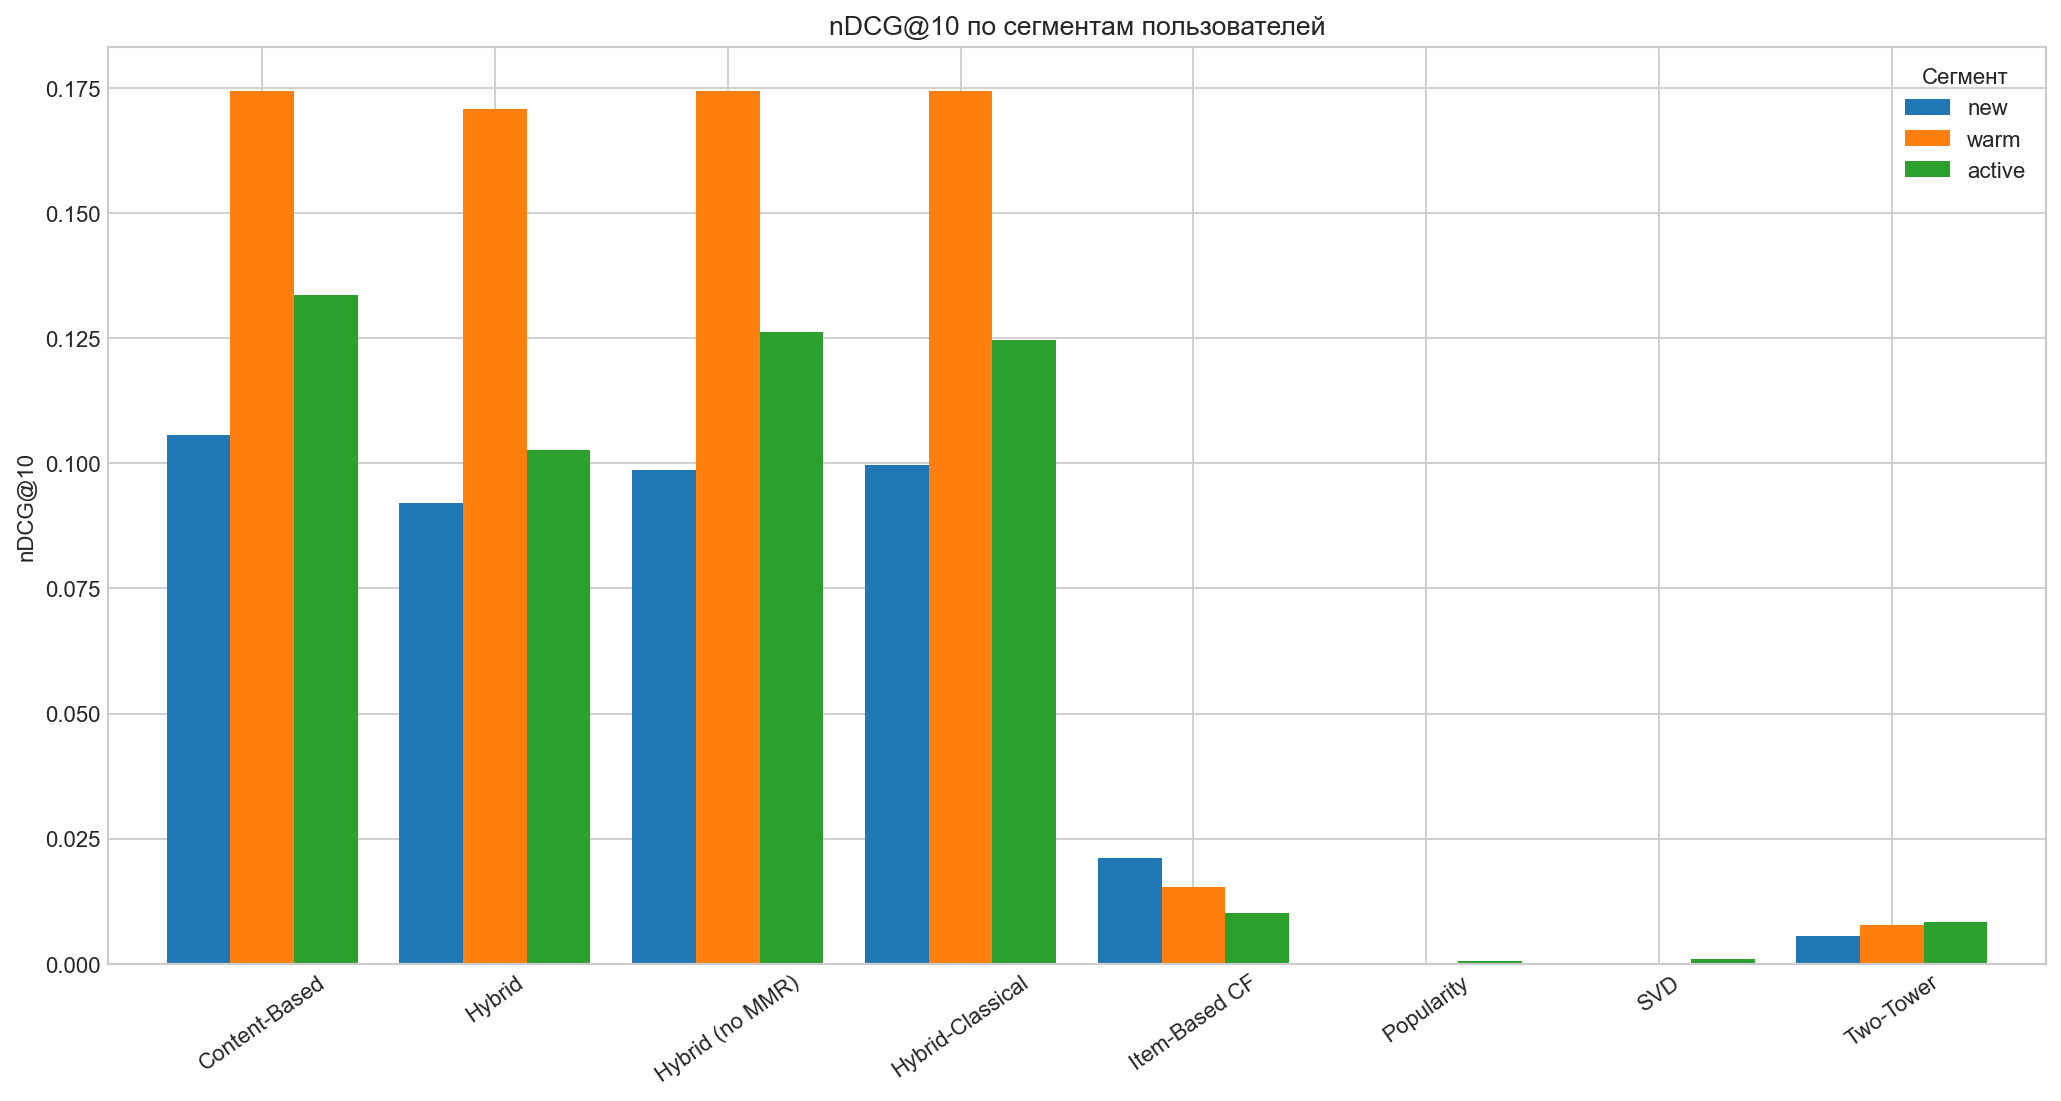

In [11]:
display(Image(filename=str(REPORTS / 'figures/07_segment_ndcg.png')))

## 7. Проверка персональной выдачи

Ниже загружается сериализованный гибрид и формируется новый список. `hybrid_score` — взвешенный нормированный score; исходные score моделей приведены в собственных шкалах и не должны сравниваться напрямую.

In [12]:
hybrid = joblib.load(ARTIFACTS / 'hybrid.joblib')
example = json.loads((ARTIFACTS / 'examples.json').read_text(encoding='utf-8'))
user_id = int(example['user_id'])
recommendations = hybrid.recommend(user_id=user_id, n=10)
catalog = pd.read_csv(ROOT / 'data/raw/books.csv', low_memory=False).set_index('id')
rows = []
for rank, (book_id, score) in enumerate(recommendations, 1):
    rows.append({'rank': rank, 'book_id': book_id, 'title': catalog.loc[book_id, 'title'],
                 'authors': catalog.loc[book_id, 'authors'], 'score': score})
print('User:', user_id, '| segment:', hybrid.segment_for_user(user_id))
pd.DataFrame(rows)

User: 6630 | segment: active


,rank,book_id,title,authors,score
0,1,243,Misery,Stephen King,0.500880
1,2,209,"The Silence of the Lambs (Hannibal Lecter, #2)",Thomas Harris,0.439454
2,3,2352,The Regulators,"Richard Bachman, Stephen King",0.369399
3,4,6361,There's Treasure Everywhere: A Calvin and Hobb...,Bill Watterson,0.215561
4,5,7927,"The Akhenaten Adventure (Children of the Lamp,...",P.B. Kerr,0.219345
5,6,201,"The Lost Symbol (Robert Langdon, #3)",Dan Brown,0.272436
6,7,3177,"The Realms of the Gods (Immortals, #4)",Tamora Pierce,0.226733
7,8,7947,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem",0.192497
8,9,944,Desperation,Stephen King,0.264749
9,10,4067,The Eight (The Eight #1),Katherine Neville,0.207584


## 8. Выводы

Лидер определяется по фактическому test nDCG, а не по предположению о преимуществе нейросети. Вклад Two-Tower оценивается разницей Hybrid (no MMR) и Hybrid-Classical без влияния MMR, вклад MMR — разницей Hybrid и Hybrid (no MMR). Для выбора модели учитываются одновременно nDCG, ILD, novelty, coverage и сегмент. Полный критический разбор и ограничения находятся в `reports/REPORT.md`.

In [13]:
indexed = metrics.set_index('model')
best = indexed['ndcg_at_k'].idxmax()
print('Лидер по nDCG@10:', best, indexed.loc[best, 'ndcg_at_k'])
print('Вклад нейросети в nDCG без MMR:', indexed.loc['Hybrid (no MMR)', 'ndcg_at_k'] - indexed.loc['Hybrid-Classical', 'ndcg_at_k'])
print('Изменение ILD от MMR:', indexed.loc['Hybrid', 'ild_at_k'] - indexed.loc['Hybrid (no MMR)', 'ild_at_k'])
print('Изменение nDCG от MMR:', indexed.loc['Hybrid', 'ndcg_at_k'] - indexed.loc['Hybrid (no MMR)', 'ndcg_at_k'])

Лидер по nDCG@10: Content-Based 0.14042941
Вклад нейросети в nDCG без MMR: 0.0005130799999999991
Изменение ILD от MMR: 0.05651602999999994
Изменение nDCG от MMR: -0.013541269999999994


## 9. Воспроизведение

- `python scripts/train.py` — обучение всего pipeline;
- `python scripts/train.py --reuse-classical` — пересчёт новых компонентов;
- `pytest -q` — тесты;
- `python scripts/validate_artifacts.py` — inference smoke-test.

Ограничения: случайный split без времени, шумные теги, uniform negative sampling, offline-метрики вместо A/B-теста. Следующий шаг — актуальные временные данные и оценка влияния на добавление в список чтения и дочитывание.